In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel("customer_shopping_behavior.xlsx.xlsx")

In [9]:
# First 5 Rows
df.head()

,Transaction ID,Customer ID,Purchase Date,Age,Gender,Location,Online/Offline,Online Store,Category,Item Purchased,...,Festival/Sale,Shipping Charge (â‚¹),Delivery Speed,Delivery Time (Days),Subscription Status,Payment Method,Review Rating,Return Status,Previous Purchases,Frequency of Purchases
0,TXN500000,CUST001440,2023-07-22,52,Other,Indore,Offline,In-Store Purchase,Clothing,Jeans,...,Standard Day,0,N/A (Offline),0,No,Credit Card,5,Not Returned,2,Quarterly
1,TXN500001,CUST002326,2023-01-16,19,Female,Bhubaneswar,Online,Ajio,Clothing,Jacket,...,Standard Day,0,Express,1,No,Debit Card,4,Returned,3,Quarterly
2,TXN500002,CUST002680,2023-01-24,40,Male,Bangalore,Online,Myntra,Clothing,Saree,...,Standard Day,0,Standard,7,Yes,Cash on Delivery,4,Not Returned,13,Monthly
3,TXN500003,CUST001098,2024-09-06,46,Female,Ahmedabad,Offline,In-Store Purchase,Clothing,Jeans,...,Standard Day,0,N/A (Offline),0,No,UPI,3,Not Returned,1,Rarely
4,TXN500004,CUST003158,2023-10-18,62,Female,Pune,Online,Flipkart,Accessories,Belt,...,Standard Day,0,Standard,6,Yes,UPI,3,Not Returned,3,Quarterly


In [10]:
#information about Data 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Transaction ID          10000 non-null  str           
 1   Customer ID             10000 non-null  str           
 2   Purchase Date           10000 non-null  datetime64[us]
 3   Age                     10000 non-null  int64         
 4   Gender                  10000 non-null  str           
 5   Location                10000 non-null  str           
 6   Online/Offline          10000 non-null  str           
 7   Online Store            10000 non-null  str           
 8   Category                10000 non-null  str           
 9   Item Purchased          10000 non-null  str           
 10  Brand                   10000 non-null  str           
 11  Color                   10000 non-null  str           
 12  Size                    10000 non-null  object        
 13

In [12]:
#Dataset Dimension
print("Shape:",df.shape)

Shape: (10000, 26)


In [13]:
#Column Names
print("Column Names\n")
print(df.columns)

Column Names

Index(['Transaction ID', 'Customer ID', 'Purchase Date', 'Age', 'Gender',
       'Location', 'Online/Offline', 'Online Store', 'Category',
       'Item Purchased', 'Brand', 'Color', 'Size', 'Quantity',
       'Purchase Amount (â‚¹)', 'Discount (%)', 'Festival/Sale',
       'Shipping Charge (â‚¹)', 'Delivery Speed', 'Delivery Time (Days)',
       'Subscription Status', 'Payment Method', 'Review Rating',
       'Return Status', 'Previous Purchases', 'Frequency of Purchases'],
      dtype='str')


In [14]:
#Data Types
print("Data Types\n")
print(df.dtypes)

Data Types

Transaction ID                       str
Customer ID                          str
Purchase Date             datetime64[us]
Age                                int64
Gender                               str
Location                             str
Online/Offline                       str
Online Store                         str
Category                             str
Item Purchased                       str
Brand                                str
Color                                str
Size                              object
Quantity                           int64
Purchase Amount (â‚¹)              int64
Discount (%)                       int64
Festival/Sale                        str
Shipping Charge (â‚¹)              int64
Delivery Speed                       str
Delivery Time (Days)               int64
Subscription Status                  str
Payment Method                       str
Review Rating                      int64
Return Status                        str
Prev

In [15]:
#Missing Value
print("Missing Values\n")
print(df.isnull().sum())

Missing Values

Transaction ID            0
Customer ID               0
Purchase Date             0
Age                       0
Gender                    0
Location                  0
Online/Offline            0
Online Store              0
Category                  0
Item Purchased            0
Brand                     0
Color                     0
Size                      0
Quantity                  0
Purchase Amount (â‚¹)     0
Discount (%)              0
Festival/Sale             0
Shipping Charge (â‚¹)     0
Delivery Speed            0
Delivery Time (Days)      0
Subscription Status       0
Payment Method            0
Review Rating             0
Return Status             0
Previous Purchases        0
Frequency of Purchases    0
dtype: int64


In [16]:
#remove Duplicates
print("Duplicate values\n")
print(df.duplicated().sum())

Duplicate values

0


In [17]:
#Statistical Summary
print("Statistical Summary\n")
print(df.describe())

Statistical Summary

                    Purchase Date           Age      Quantity  \
count                       10000  10000.000000  10000.000000   
mean   2023-12-31 02:11:36.960000     41.095400      1.425900   
min           2023-01-01 00:00:00     18.000000      1.000000   
25%           2023-06-29 00:00:00     29.000000      1.000000   
50%           2023-12-30 00:00:00     41.000000      1.000000   
75%           2024-07-01 00:00:00     53.000000      2.000000   
max           2024-12-30 00:00:00     64.000000      4.000000   
std                           NaN     13.537475      0.725921   

       Purchase Amount (â‚¹)  Discount (%)  Shipping Charge (â‚¹)  \
count           10000.000000  10000.000000           10000.000000   
mean             6467.694500      8.704500              20.472500   
min               107.000000      0.000000               0.000000   
25%              1659.000000      4.000000               0.000000   
50%              3491.000000      8.000000      

In [22]:
df['Purchase Date'] = pd.to_datetime(df['Purchase Date'])
Monthly_sales = (df.groupby(df['Purchase Date'].dt.to_period('M'))['Purchase Amount (â‚¹)'].sum())
Monthly_sales.head()

Purchase Date
2023-01    2496771
2023-02    2248695
2023-03    2837727
2023-04    2543377
2023-05    2881711
Freq: M, Name: Purchase Amount (â‚¹), dtype: int64

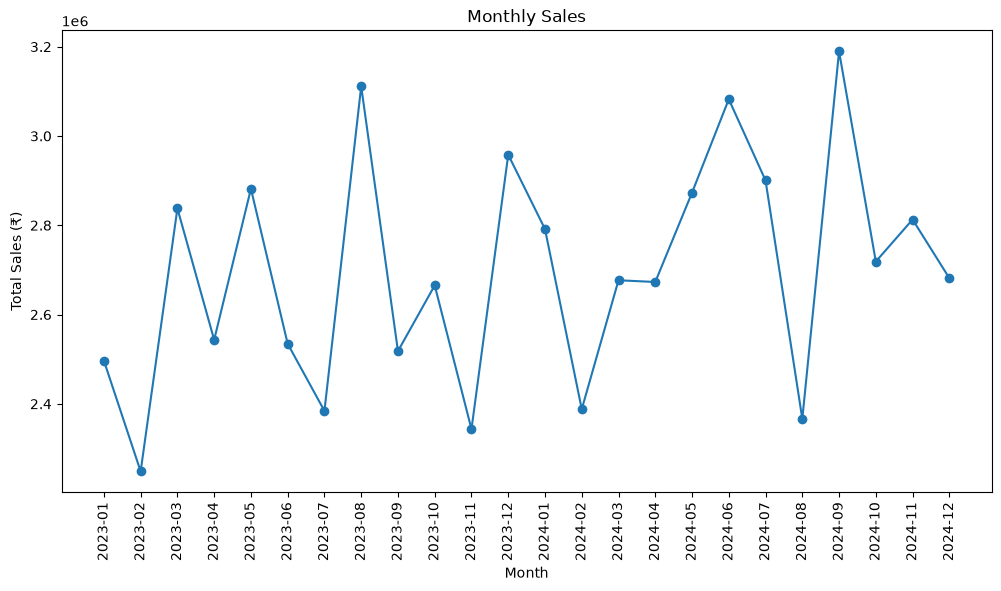

In [ ]:
#ploting graph based on monthly sales
plt.figure(figsize=(12,6))
plt.plot(Monthly_sales.index.astype(str), Monthly_sales.values, marker='o')
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.xticks(rotation=90)
plt.ylabel("Total Sales (₹)")
plt.show()

### Observation – Monthly Sales Trend

(The line chart illustrates the monthly revenue generated
throughout the analysis period.

- Highest sales month: [September 2024]
- Lowest sales month: [February 2023]
- Overall trend: [Fluctuating with a general upward trend, indicating growth in sales over time.]
Business Insight:
This analysis helps businesses identify high-performing
and low-performing months and plan inventory and
marketing campaigns accordingly.)

In [32]:
#Quarterly Sales Analysis
Quarterly_sales = (df.groupby(df['Purchase Date'].dt.to_period('Q')))['Purchase Amount (â‚¹)'].sum()
Quarterly_sales.head()

Purchase Date
2023Q1    7583193
2023Q2    7959604
2023Q3    8013584
2023Q4    7966612
2024Q1    7856278
Freq: Q-DEC, Name: Purchase Amount (â‚¹), dtype: int64

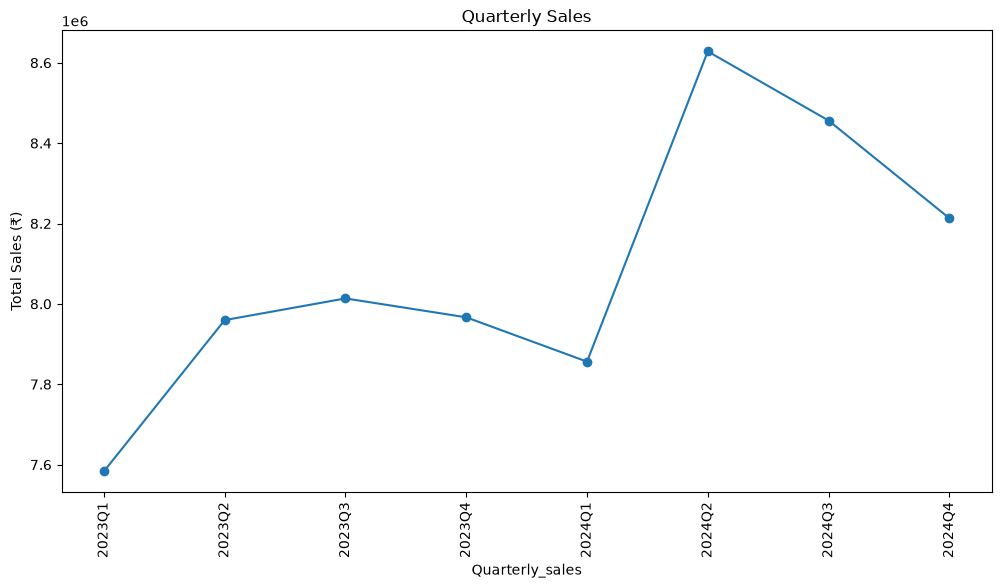

In [ ]:
#Quarterly sales graph
plt.figure(figsize=(12,6))
plt.plot(Quarterly_sales.index.astype(str), Quarterly_sales.values, marker='o')
plt.title("Quarterly Sales")
plt.xlabel("Quarterly_sales")
plt.xticks(rotation = 90)
plt.ylabel("Total Sales (₹)")
plt.show()


### Observation – Quarterly Sales Trend

(- Highest revenue quarter: [Q2 of 2024]
- Lowest revenue quarter: [Q1 of 2023]
- Overall trend: [Fluctuating with a general upward trend, indicating growth in sales over time.]

Business Insight:

Quarterly sales analysis helps businesses identify
seasonal demand patterns and plan inventory,
promotional campaigns and resource allocation.)

In [5]:
#Distribution of age of customer
bins = [0,18, 25, 35, 45, 55, 100]
Labels = ['Below 18', '18-25', '26-35', '36-45', '46-55', 'Above 55']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=Labels, right=False)
Age_distribution = df['Age Group'].value_counts().sort_index()
print(Age_distribution)

Age Group
Below 18       0
18-25       1430
26-35       2101
36-45       2142
46-55       2146
Above 55    2181
Name: count, dtype: int64


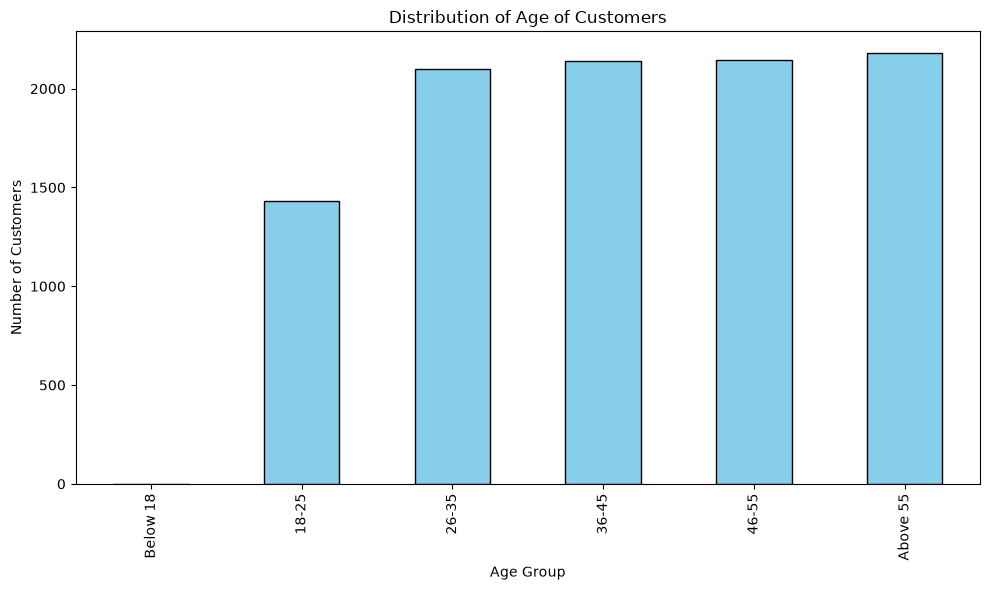

In [9]:
plt.figure(figsize=(10,6))
Age_distribution.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Distribution of Age of Customers")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [10]:
#Customer Distrubution By gender
df['Gender'].value_counts().sort_index()
print(df['Gender'].value_counts().sort_index())

Gender
Female    4839
Male      4790
Other      371
Name: count, dtype: int64


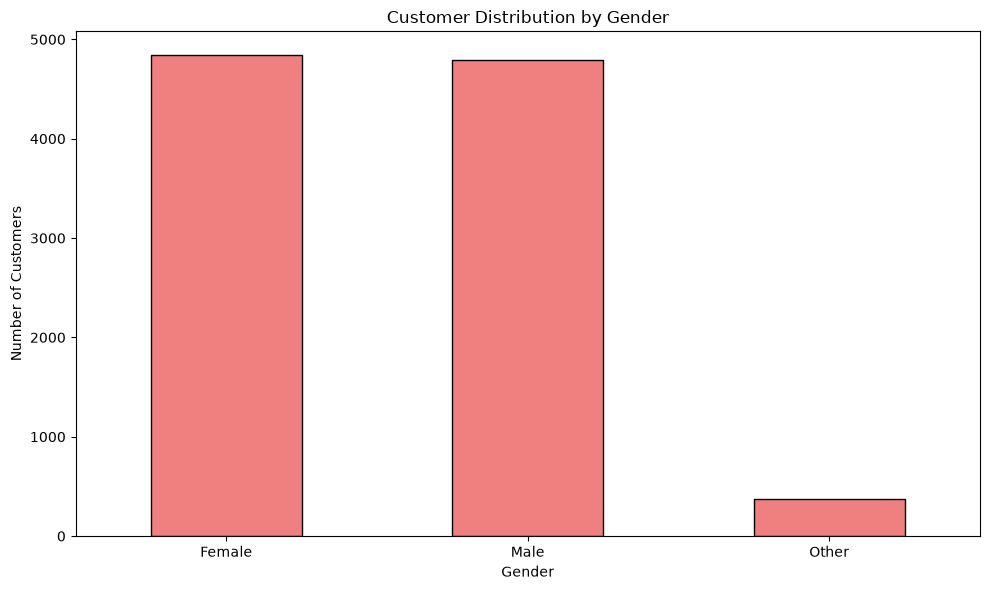

In [11]:
plt.figure(figsize=(10,6))
Gender_distribution = df['Gender'].value_counts()
Gender_distribution.plot(kind = 'bar', color='lightcoral', edgecolor='black')
plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
### Observation – Customer Demographics

(1. The highest purchase activity comes from the
   Above 55 age group.

2. The gender with the highest number of transactions
   is [Female].

Business Insight:

Understanding customer demographics helps businesses
design targeted marketing campaigns and personalize
their product offerings.)

In [13]:
#Top 10 Best Selling Products
top_products=df.groupby('Item Purchased')['Purchase Amount (â‚¹)'].sum().sort_values(ascending=False).head(10)
print(top_products)

Item Purchased
Sneakers         15583108
Running Shoes    14080001
Saree             6331319
Jacket            4634764
Boots             2681133
Kurta             2565357
Formal Shoes      2348392
Hoodie            2168269
Sunglasses        1534805
Heels             1487007
Name: Purchase Amount (â‚¹), dtype: int64


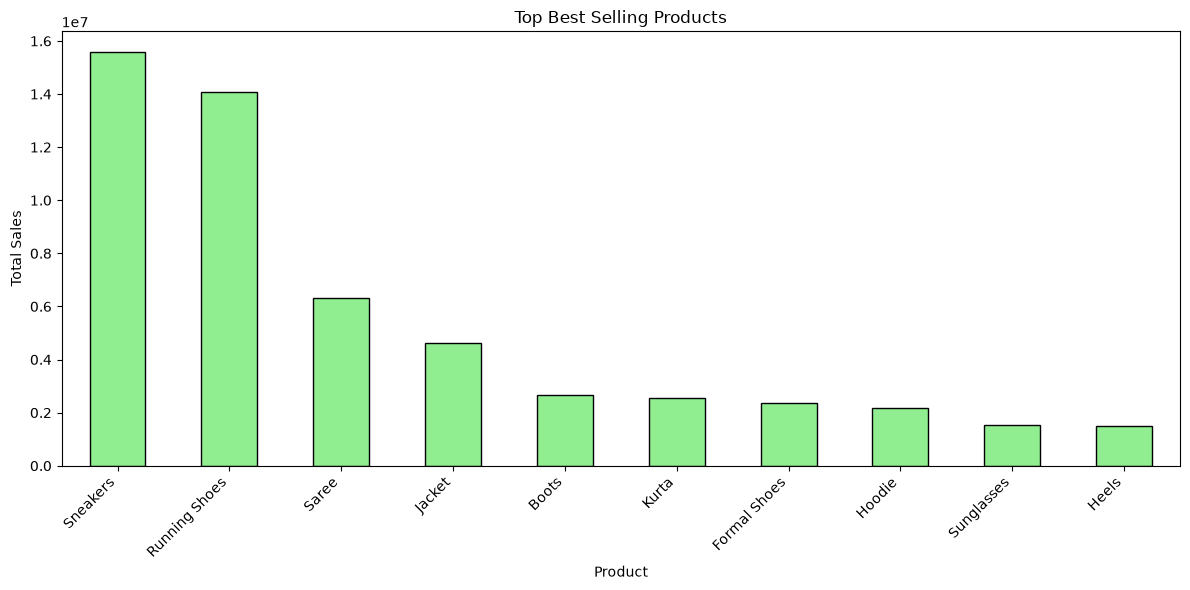

In [14]:
plt.figure(figsize=(12,6))
top_products.plot(kind = 'bar',color='Lightgreen', edgecolor='black')
plt.title("Top Best Selling Products")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
### Observation – Top 10 Best-Selling Products

(- The most frequently purchased product is [Sneakers].
- The product with the lowest quantity among the top 10 is [Heels].
- The top-selling products contribute significantly to overall sales volume.

Business Insight:

Businesses can prioritize inventory management for
high-demand products, reduce stock shortages, and plan
product-specific promotions.)

In [16]:
#revenue By Product Category
revenue_by_category = (
    df.groupby('Category')['Purchase Amount (â‚¹)']
      .sum()
      .sort_values(ascending=False)
)
print(revenue_by_category)

Category
Footwear       37462463
Clothing       21809421
Accessories     5405061
Name: Purchase Amount (â‚¹), dtype: int64


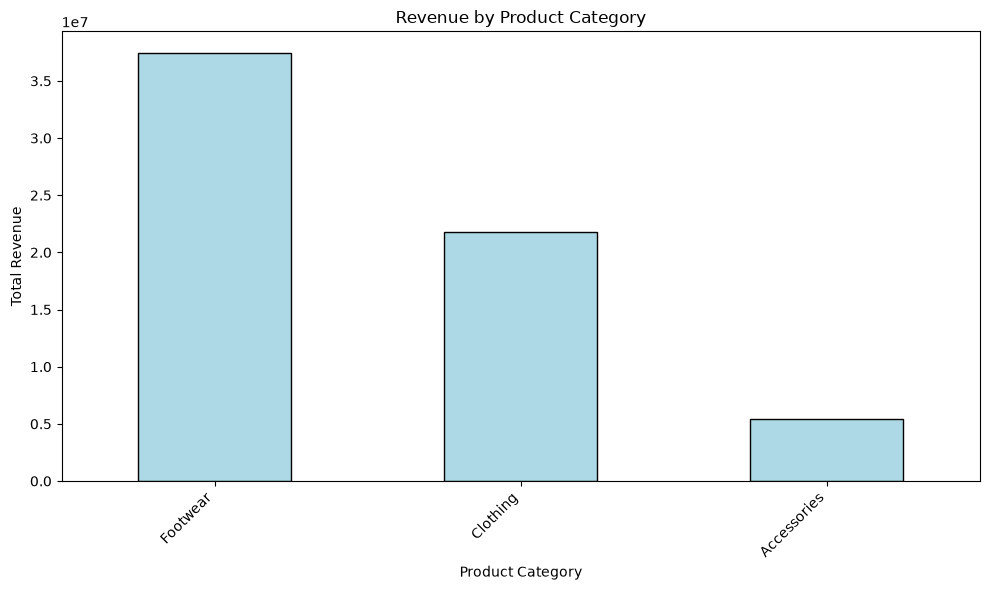

In [17]:
plt.figure(figsize=(10,6))
revenue_by_category.plot(kind='bar', color='Lightblue', edgecolor='black')
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [3]:
#Coorelation Heatmap
numeric_df = df.select_dtypes(include='number')
print(numeric_df.columns)


Index(['Age', 'Quantity', 'Purchase Amount (â‚¹)', 'Discount (%)',
       'Shipping Charge (â‚¹)', 'Delivery Time (Days)', 'Review Rating',
       'Previous Purchases'],
      dtype='str')


In [4]:
coorelation_matrix = numeric_df.corr()
print(coorelation_matrix)

                            Age  Quantity  Purchase Amount (â‚¹)  \
Age                    1.000000 -0.009600               0.003135   
Quantity              -0.009600  1.000000               0.369169   
Purchase Amount (â‚¹)  0.003135  0.369169               1.000000   
Discount (%)           0.010799  0.000124               0.017517   
Shipping Charge (â‚¹)  0.004222 -0.008709              -0.001033   
Delivery Time (Days)  -0.002991 -0.001137               0.001521   
Review Rating          0.019353  0.003847               0.132791   
Previous Purchases     0.003176  0.003419               0.001391   

                       Discount (%)  Shipping Charge (â‚¹)  \
Age                        0.010799               0.004222   
Quantity                   0.000124              -0.008709   
Purchase Amount (â‚¹)      0.017517              -0.001033   
Discount (%)               1.000000              -0.022761   
Shipping Charge (â‚¹)     -0.022761               1.000000   
Delivery Time (

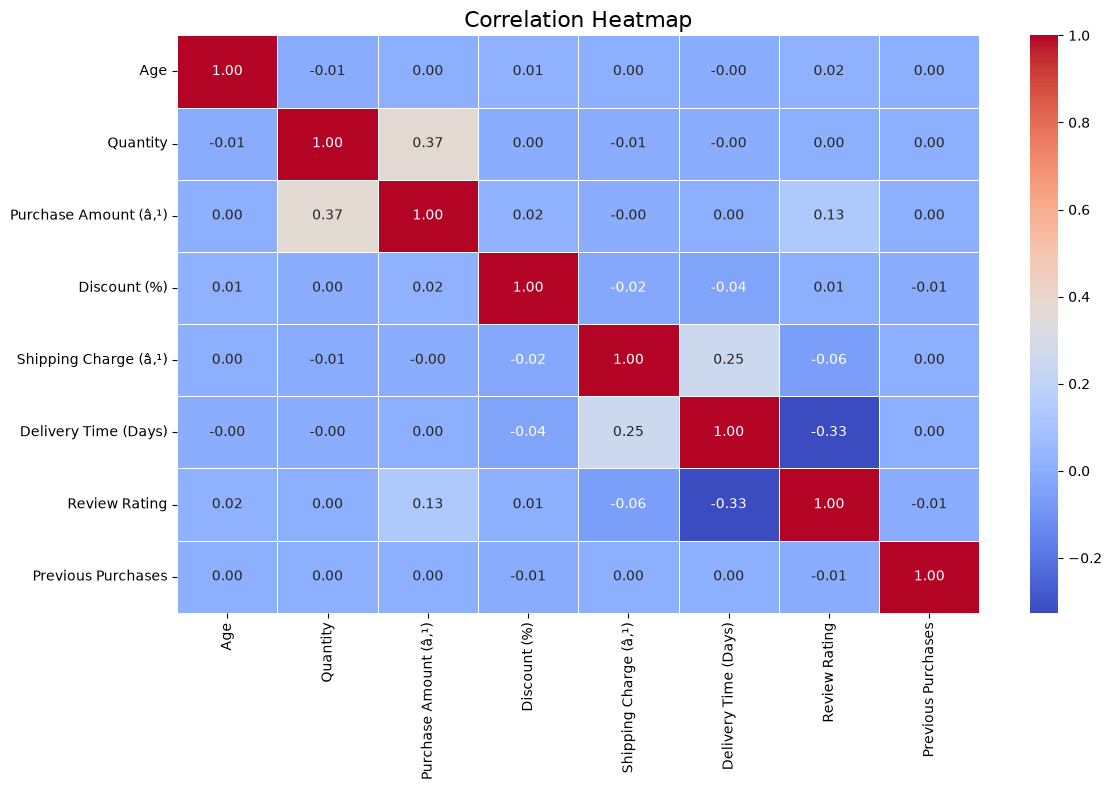

In [6]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    coorelation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
### Observation – Correlation Heatmap

(- The strongest positive correlation is between **Quantity and Purchase Amount (0.37)**,
indicating that higher quantities purchased tend to be associated with higher purchase amounts.
- The strongest negative correlation is between **Delivery Time and Review Rating (-0.33)**, 
suggesting that longer delivery times tend to be associated with lower customer ratings.
- Variables such as Age and Purchase Amount (0.00), and Age and Quantity (-0.01), 
show negligible linear correlation.

**Business Insight:**

Correlation analysis helps identify relationships between numerical variables. 
The business should monitor delivery performance because longer delivery times are associated with lower customer ratings.
 It can also analyse purchasing quantities to better understand revenue patterns.)

In [7]:
#Return Package by Category
return_rate = (
    df.groupby('Category')['Return Status']
    .apply(lambda x: (x == 'Returned').mean() * 100)
    .sort_values(ascending=False)
)

print(return_rate.round(2))

Category
Footwear       19.09
Clothing       18.80
Accessories    10.12
Name: Return Status, dtype: float64


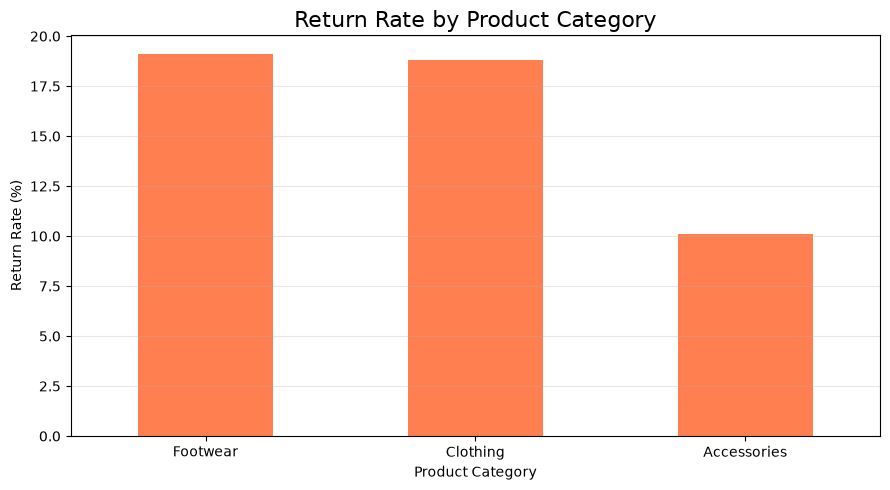

In [8]:
plt.figure(figsize=(9, 5))

return_rate.plot(kind='bar', color='coral')

plt.title('Return Rate by Product Category', fontsize=16)
plt.xlabel('Product Category')
plt.ylabel('Return Rate (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
### Additional Visualization – Return Rate by Product Category

( **Observation:**

- Footwear has the highest return rate at approximately 19.09%.
- Clothing follows with a return rate of 18.80%.
- Accessories have the lowest return rate at approximately 10.12%.

**Non-Obvious Business Insight:**

Footwear and clothing have considerably higher return rates than accessories. 
This suggests that the business should investigate possible reasons such as size mismatches, product quality, or differences between product descriptions and customer expectations.

**Business Recommendation:**

The business should improve size guides, product descriptions and quality checks for footwear 
and clothing to potentially reduce product returns and improve customer satisfaction.)